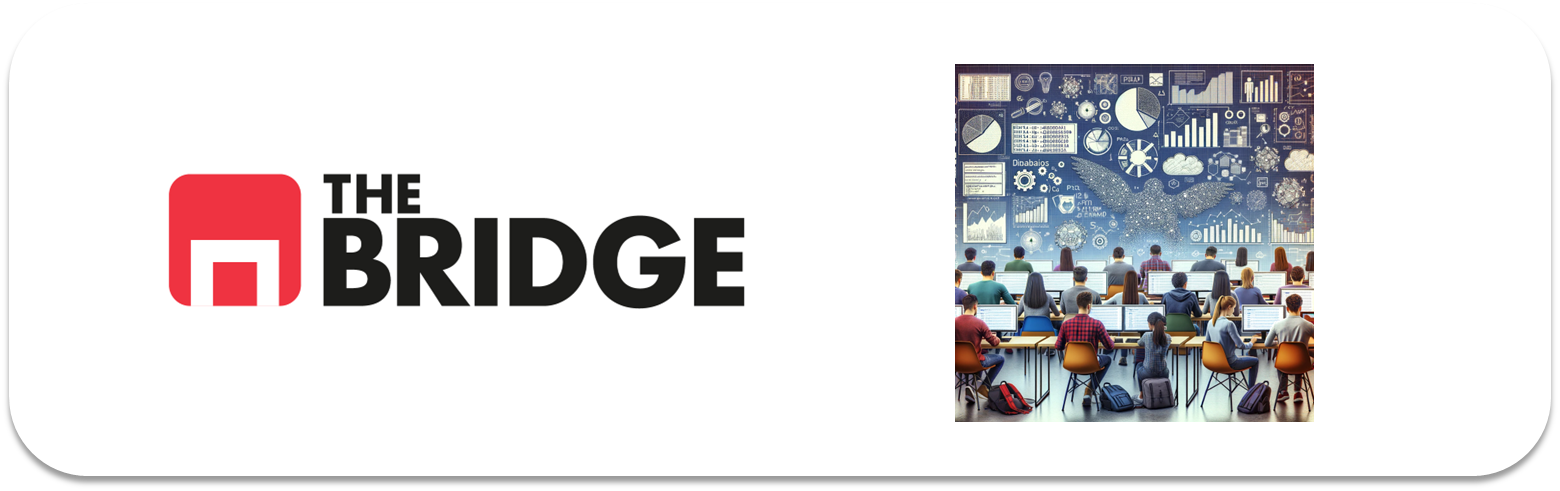

## APLICACIÓN PRÁCTICA: **De pandas a transformers de sklearn**

Partimos del ejercicio del Titanic que ya resolvimos con pandas (predecir la supervivencia de los pasajeros con un modelo de clasificación) y vamos a repetir el flujo completo sustituyendo los pasos de preprocesado manuales por **transformers de sklearn**:

| Paso | Con pandas | Con sklearn |
|---|---|---|
| Imputar nulos | `fillna(train[col].median())` | `SimpleImputer` |
| Codificar categóricas | `pd.get_dummies` | `OneHotEncoder` |
| Transformar numéricas | `np.log1p(...)` | `FunctionTransformer` |
| Escalar | `(x - media) / std` a mano | `StandardScaler` |

La idea clave es siempre la misma: **los transformers aprenden (`fit`) solo con train y aplican (`transform`) lo aprendido tanto a train como a test**, sin tener que guardarnos a mano medias, modas o columnas.

Los pasos que seguiremos son los habituales de un proyecto de ML: problema de negocio, carga, limpieza, split, EDA, dataprep, modelado y evaluación.

---

## **1. Problema de negocio**

-> Predecir la supervivencia de nuevos pasajer@s no conocidos en el manifiesto orignal del Titanic (típico problema de inferencia de muestra a población) <-

## **2. Problema técnico**

Convertimos nuestro problema de negocio en un problema técnico de Machine Learning (idealmente). En este caso nos encontramos ante un problema de tipo:  
- Aprendizaje Supervisado (tengo etiquetas objetivo)  

	- Clasificación (quiero predecir la pertenencia a clases)

## **3. Importar librerías**

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## **4. Conseguir los datos**

Carga y exploración inicial.

In [25]:
df = pd.read_csv("../data/titanic.csv")
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


## **5. Limpieza y exploración inicial**

### 5.1 Quitamos las columnas repetidas o redundantes

Y nos cargamos deck porque tiene muchos nulos, aunque también se podría usar para generar una binaria que indique si se conoce o no el deck de cada persona.

In [27]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [28]:
cols_to_include = ["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "who", "adult_male", "embark_town", "alone"]

In [29]:
df = df[cols_to_include].copy()
df

,survived,pclass,sex,age,sibsp,parch,fare,who,adult_male,embark_town,alone
0,0,3,male,22.0,1,0,7.2500,man,True,Southampton,False
1,1,1,female,38.0,1,0,71.2833,woman,False,Cherbourg,False
2,1,3,female,26.0,0,0,7.9250,woman,False,Southampton,True
3,1,1,female,35.0,1,0,53.1000,woman,False,Southampton,False
4,0,3,male,35.0,0,0,8.0500,man,True,Southampton,True
...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,man,True,Southampton,True
887,1,1,female,19.0,0,0,30.0000,woman,False,Southampton,True
888,0,3,female,NaN,1,2,23.4500,woman,False,Southampton,False
889,1,1,male,26.0,0,0,30.0000,man,True,Cherbourg,True


### 5.2 Evaluamos nulos, cardinalidad, valores únicos, etc.

In [30]:
df.isna().mean() * 100

survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
parch           0.000000
fare            0.000000
who             0.000000
adult_male      0.000000
embark_town     0.224467
alone           0.000000
dtype: float64

In [31]:
df.nunique()

survived         2
pclass           3
sex              2
age             88
sibsp            7
parch            7
fare           248
who              3
adult_male       2
embark_town      3
alone            2
dtype: int64

In [32]:
df.nunique() / len(df) * 100

survived        0.224467
pclass          0.336700
sex             0.224467
age             9.876543
sibsp           0.785634
parch           0.785634
fare           27.833895
who             0.336700
adult_male      0.224467
embark_town     0.336700
alone           0.224467
dtype: float64

## **6. Tipificación de variables**

Aquí deberíamos hacer el esquema o tabla resumen de las variables (siempre que tenga sentido, no hagamos un esquemas de miles de variables please ;) ) para diferenciar numéricas de categóricas independientemente de su tipo en pandas.

### 6.1 Identificamos target, numéricas y categóricas

In [33]:
target = "survived"

In [34]:
col_numericas = ["age", "sibsp", "parch", "fare"]
col_numericas

['age', 'sibsp', 'parch', 'fare']

In [35]:
col_categoricas = [col for col in df.columns if col not in col_numericas and col not in target]
col_categoricas

['pclass', 'sex', 'who', 'adult_male', 'embark_town', 'alone']

## **7. Separamos en train y test**

En el enuncidado nos pedían estratificar train y test usando la columna de la ciudad de embarque.

Sin embargo, **esto es una trampa para demostrar que no podemos estratificar usando una columna con nulos** (dos nulos en este caso concreto).

In [36]:
# # Esta celda dará error por los nulos en la columna del embarque

# from sklearn.model_selection import train_test_split

# train_set, test_set = train_test_split(df, test_size=0.2, random_state=42, stratify=df["embark_town"])

Oh nooo, tengo nulos -> o los imputo o me los cargo, ambas opciones son válidas en este caso porque son muy pocos nulos

In [37]:
df["embark_town"].value_counts(dropna=False, normalize=True)

embark_town
Southampton    0.722783
Cherbourg      0.188552
Queenstown     0.086420
NaN            0.002245
Name: proportion, dtype: float64

In [38]:
df[df["embark_town"].isna()]

,survived,pclass,sex,age,sibsp,parch,fare,who,adult_male,embark_town,alone
61,1,1,female,38.0,0,0,80.0,woman,False,NaN,True
829,1,1,female,62.0,0,0,80.0,woman,False,NaN,True


In [39]:
# # Si me los quiero cargar:

# df = df.dropna(subset=["embark_town"])

In [40]:
# Si los quiero imputar usando la moda:

mode_embark = df["embark_town"].mode()[0] # La guardo en una variable
print(mode_embark)

df["embark_town"] = df["embark_town"].fillna(mode_embark) # La uso para imputarlos

Southampton


**OJO:** imputar con la moda de **todo** el dataset antes de dividir en train y test es, técnicamente, una pequeña fuga de información (la moda incluye datos de test). Aquí lo aceptamos porque son solo dos nulos y la moda (Southampton) es abrumadora, pero la forma correcta es la que veremos enseguida con `SimpleImputer`: aprender la moda solo en train.

Comprobamos que se haya solucionado:

In [41]:
df["embark_town"].value_counts(dropna=False, normalize=True)

embark_town
Southampton    0.725028
Cherbourg      0.188552
Queenstown     0.086420
Name: proportion, dtype: float64

Y ahora sí, divido con estratificación:

In [42]:
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(df, test_size=0.2, random_state=42, stratify=df["embark_town"])

In [43]:
print(train_set.shape)
print(test_set.shape)

(712, 11)
(179, 11)


## **8. Entender el target**

SIEMPRE hay que ver cómo es nuestro target, idealmente una vez hayamos dividido en train y test, para saber a qué nos enfrentamos.

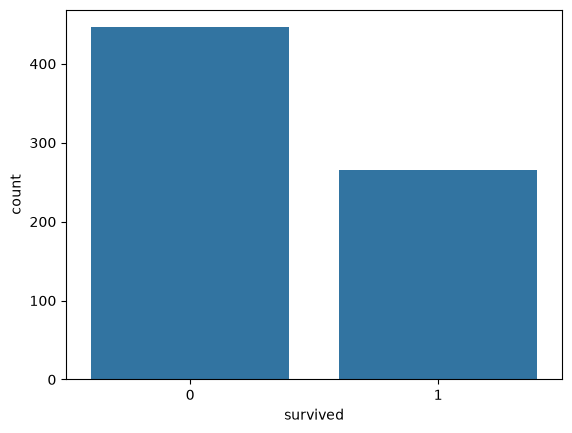

In [44]:
sns.countplot(data=train_set, x=target);

In [45]:
(train_set[target].value_counts(normalize=True)* 100).round(2)

survived
0    62.64
1    37.36
Name: proportion, dtype: float64

**Conclusión:** Target binario ligeramente desbalanceado (mayoría de la clase negativa 63/37)

Esto de aquí es "*trampa*" (porque implica mirar test y nunca debemos mirar test), pero podemos comprobar si el estratificado ha funcionado como debería comprobando las frecuencias de las ciudades de embarque en train y test.

In [46]:
train_set["embark_town"].value_counts(normalize=True)

embark_town
Southampton    0.724719
Cherbourg      0.188202
Queenstown     0.087079
Name: proportion, dtype: float64

In [47]:
test_set["embark_town"].value_counts(normalize=True)

embark_town
Southampton    0.726257
Cherbourg      0.189944
Queenstown     0.083799
Name: proportion, dtype: float64

**Conclusión:** El estratificado ha funcionado.

## **9. Mini-EDA**

Univariante, bivariante, multivariante y tests de hipótesis.

Solo cuando tenga sentido (de nuevo, cuando no tengamos miles de variables) y la profundidad del análisis dependerá del tiempo disponible, como siempre.

**IMPORTANTE:** siempre será un EDA dirigido a Machine Learning, por tanto nuestro target será el protagonista principal, y todo debe hacerse SOLO sobre el conjunto de train.

In [48]:
train_set[col_numericas].describe()

,age,sibsp,parch,fare
count,561.000000,712.000000,712.000000,712.000000
mean,30.184777,0.523876,0.356742,32.292771
std,14.732071,1.099542,0.736231,51.721504
min,0.750000,0.000000,0.000000,0.000000
25%,21.000000,0.000000,0.000000,7.895800
50%,29.000000,0.000000,0.000000,14.454200
75%,39.000000,1.000000,0.000000,30.548950
max,80.000000,8.000000,5.000000,512.329200


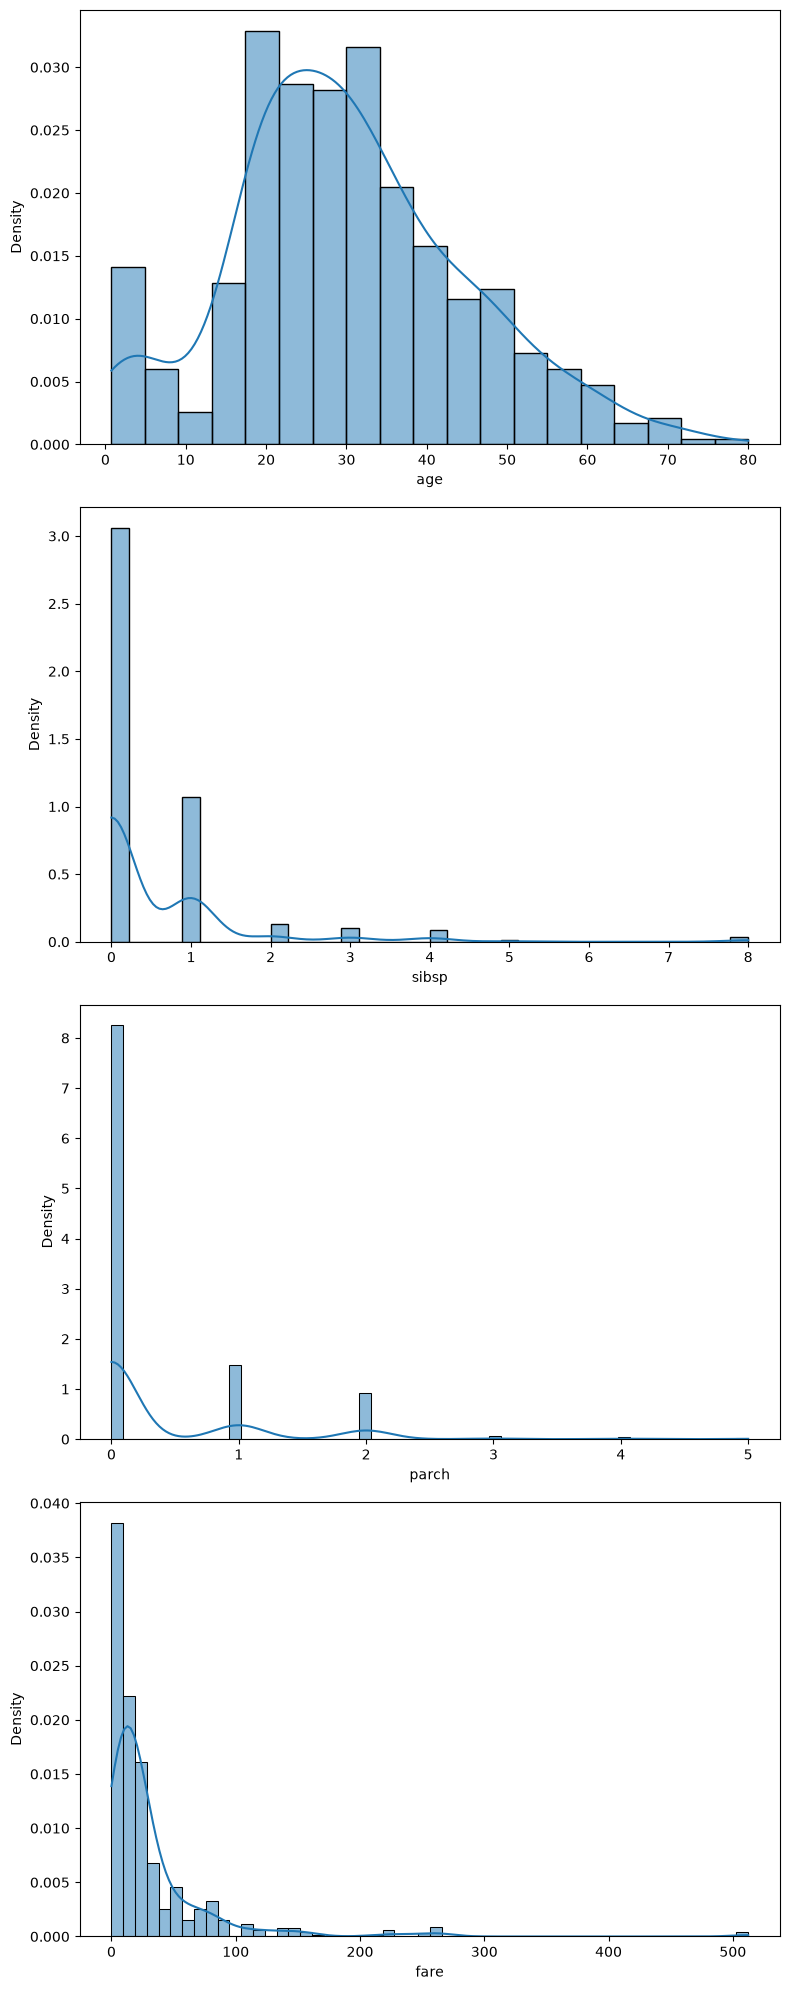

In [49]:
# Univariante numéricas

fig, axs = plt.subplots(len(col_numericas), 1, figsize=(8,20))

axs = axs.flatten()

for ax, col in zip(axs, col_numericas):
    sns.histplot(train_set, x=col, stat="density", kde=True, ax=ax)

plt.tight_layout()
plt.show()

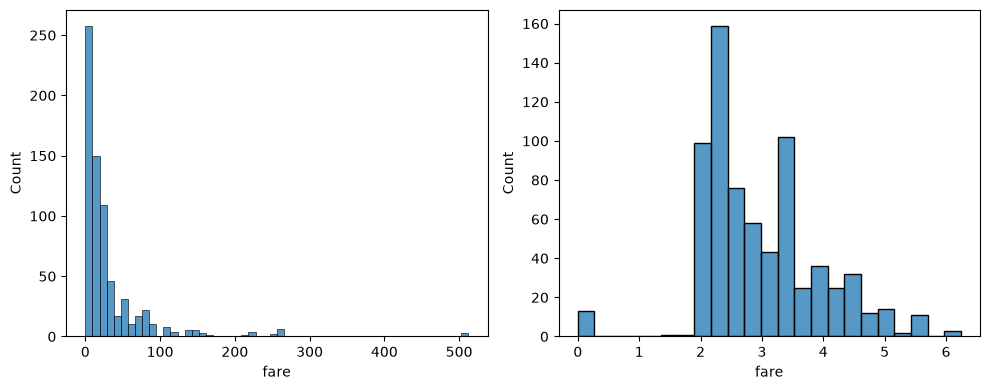

In [50]:
# Comprobamos como afectaría una transformación logarítmica a "fare"

fig, (ax0, ax1) = plt.subplots(1,2, figsize=(10,4))

sns.histplot(train_set.loc[:, "fare"], ax=ax0)
sns.histplot(np.log1p(train_set.loc[:, "fare"]), ax=ax1)
plt.tight_layout()
plt.show()

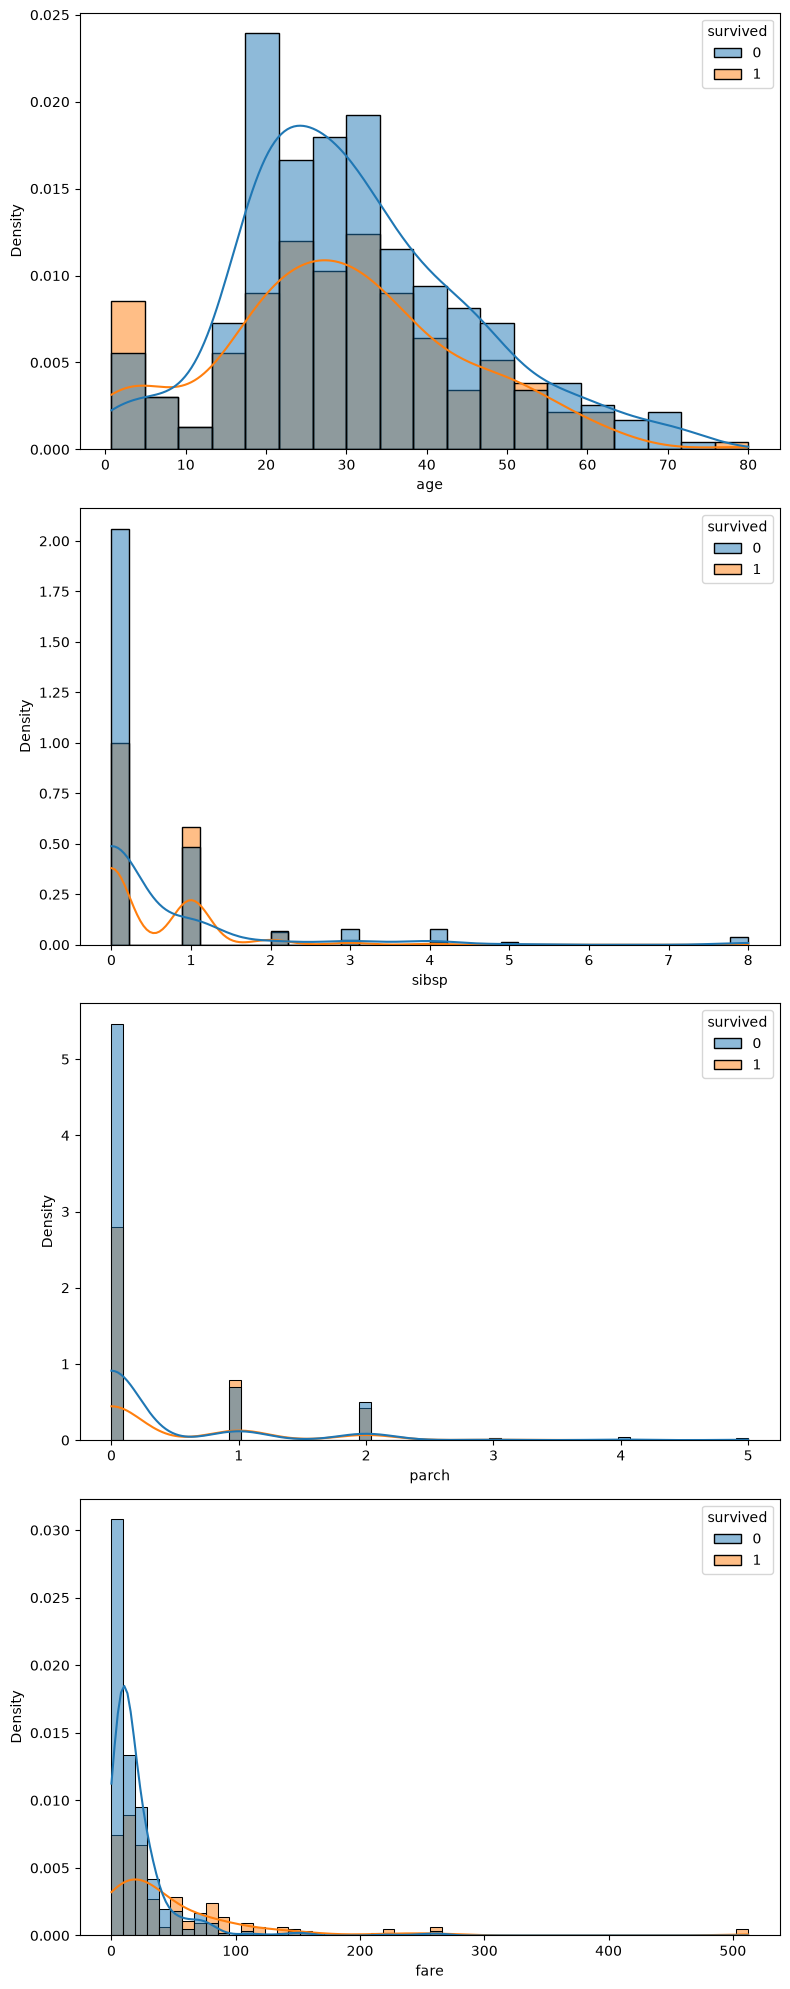

In [51]:
# Bivariante numéricas/target

fig, axs = plt.subplots(len(col_numericas), 1, figsize=(8,20))

axs = axs.flatten()

for ax, col in zip(axs, col_numericas):
    sns.histplot(train_set, x=col, hue= target, stat="density", kde=True, ax=ax)

plt.tight_layout()
plt.show()

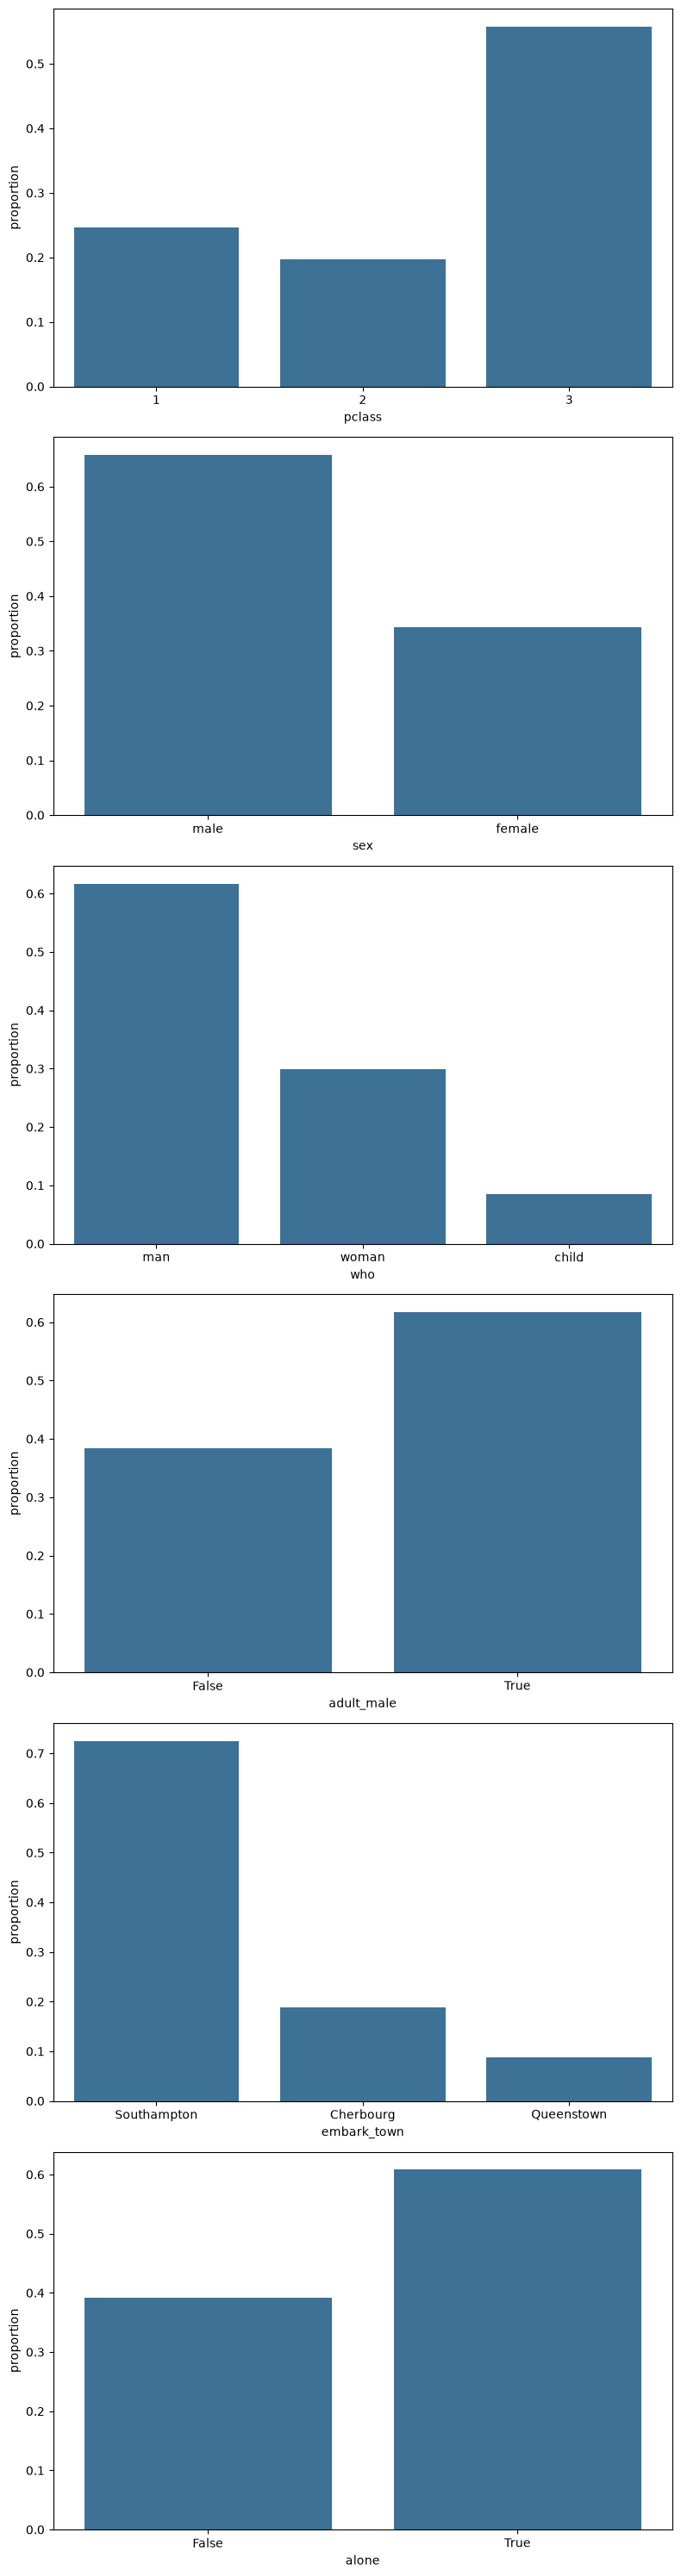

In [52]:
# Univariante categóricas

fig, axs = plt.subplots(len(col_categoricas), 1, figsize=(8,30))

axs = axs.flatten()

for ax, col in zip(axs, col_categoricas):
    sns.countplot(train_set, x=col, saturation=0.6, stat="proportion", ax=ax)

plt.tight_layout()
plt.show()

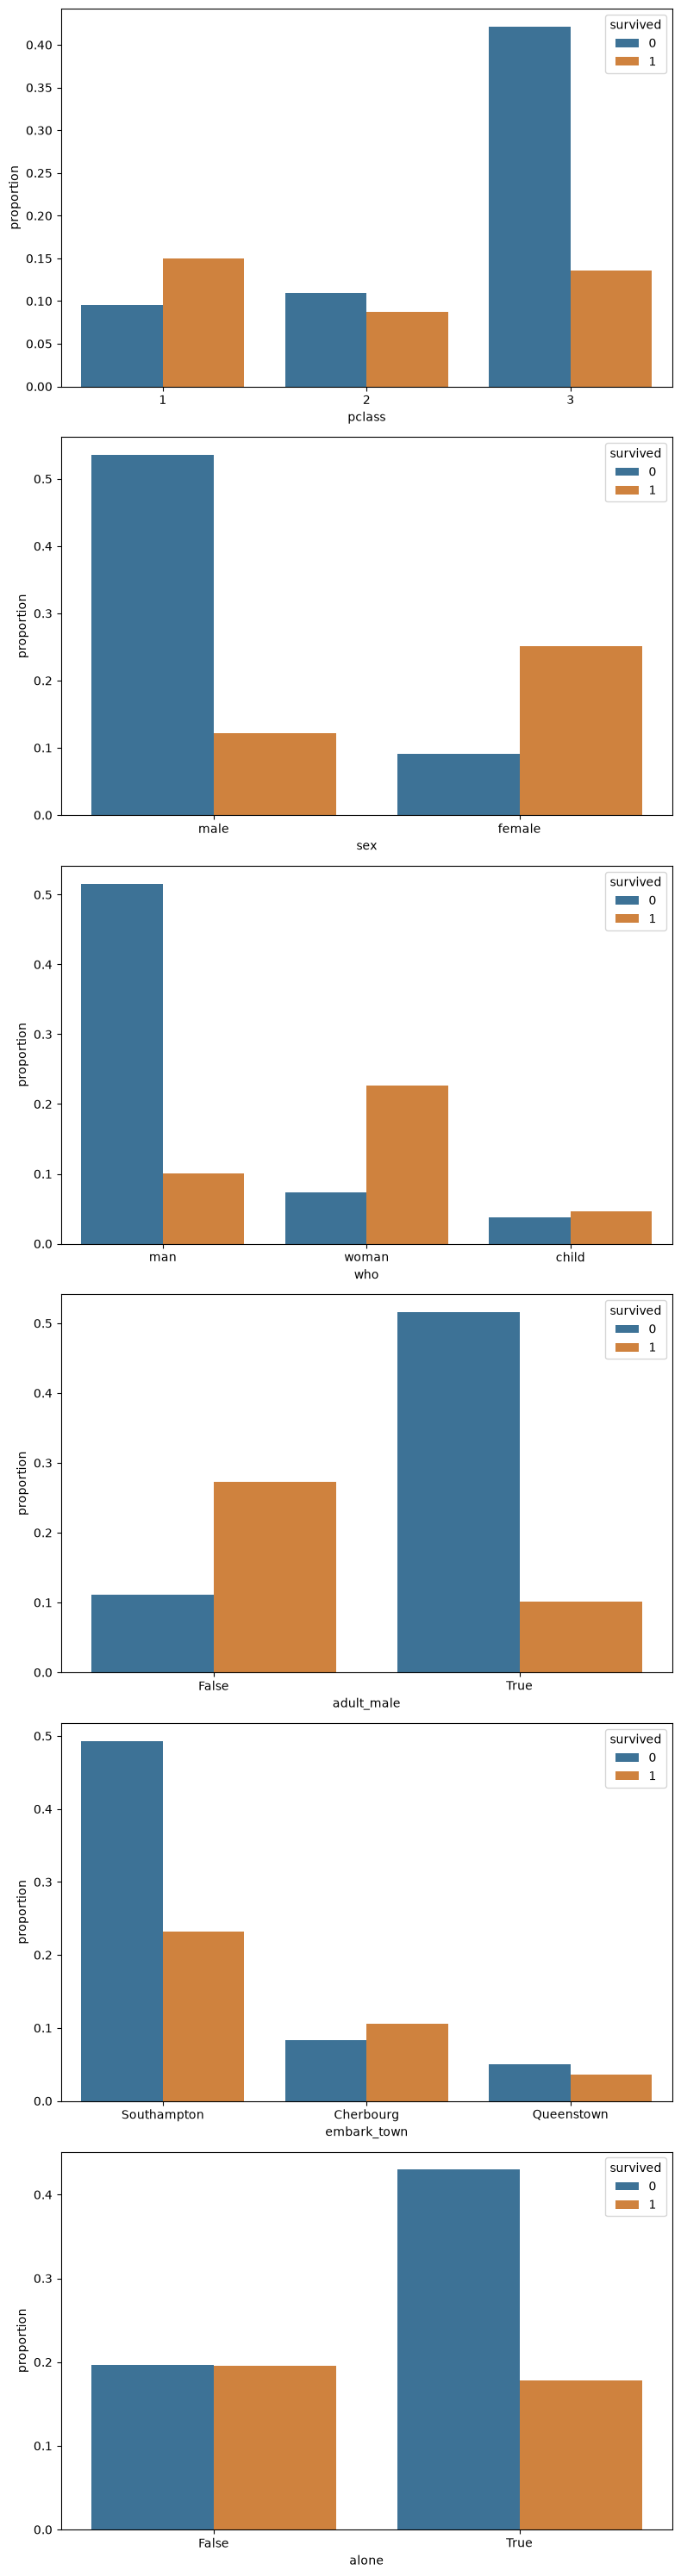

In [53]:
# Bivariante categóricas/target

fig, axs = plt.subplots(len(col_categoricas), 1, figsize=(8,30))

axs = axs.flatten()

for ax, col in zip(axs, col_categoricas):
    sns.countplot(train_set, x=col, hue=target, saturation=0.6, stat="proportion", ax=ax)

plt.tight_layout()
plt.show()

Con tiempo y cariño el análisis nos permitiría hacer una selección visual de características, en este caso seguiremos con nuestra selección actual.  

También existe la opción de utilizar tests de hipótesis como selectores automáticos de variables.

## **10. DataPrep**

Limpieza y tratamiento para ML

In [54]:
train_set

,survived,pclass,sex,age,sibsp,parch,fare,who,adult_male,embark_town,alone
838,1,3,male,32.0,0,0,56.4958,man,True,Southampton,True
621,1,1,male,42.0,1,0,52.5542,man,True,Southampton,False
282,0,3,male,16.0,0,0,9.5000,man,True,Southampton,True
275,1,1,female,63.0,1,0,77.9583,woman,False,Southampton,False
217,0,2,male,42.0,1,0,27.0000,man,True,Southampton,False
...,...,...,...,...,...,...,...,...,...,...,...
594,0,2,male,37.0,1,0,26.0000,man,True,Southampton,False
166,1,1,female,NaN,0,1,55.0000,woman,False,Southampton,False
121,0,3,male,NaN,0,0,8.0500,man,True,Southampton,True
785,0,3,male,25.0,0,0,7.2500,man,True,Southampton,True


### **10.1 Imputación de nulos**

In [55]:
train_set.isna().mean()

survived       0.000000
pclass         0.000000
sex            0.000000
age            0.212079
sibsp          0.000000
parch          0.000000
fare           0.000000
who            0.000000
adult_male     0.000000
embark_town    0.000000
alone          0.000000
dtype: float64

In [56]:
# # Imputación con pandas

# median_age = train_set["age"].median()
# train_set["age"] = train_set["age"].fillna(median_age)

In [57]:
# Imputación con transformer de sklearn

from sklearn.impute import SimpleImputer

median_imputer = SimpleImputer(strategy="median") # Mediana para numéricas
mode_imputer = SimpleImputer(strategy="most_frequent") # Moda para categóricas

In [58]:
train_set["age"].isna().sum()

np.int64(151)

In [59]:
train_set[col_numericas] = median_imputer.fit_transform(train_set[col_numericas])
test_set[col_numericas] = median_imputer.transform(test_set[col_numericas])

In [60]:
train_set[col_categoricas] = mode_imputer.fit_transform(train_set[col_categoricas])
test_set[col_categoricas] = mode_imputer.transform(test_set[col_categoricas])

In [61]:
train_set

,survived,pclass,sex,age,sibsp,parch,fare,who,adult_male,embark_town,alone
838,1,3,male,32.0,0.0,0.0,56.4958,man,True,Southampton,True
621,1,1,male,42.0,1.0,0.0,52.5542,man,True,Southampton,False
282,0,3,male,16.0,0.0,0.0,9.5000,man,True,Southampton,True
275,1,1,female,63.0,1.0,0.0,77.9583,woman,False,Southampton,False
217,0,2,male,42.0,1.0,0.0,27.0000,man,True,Southampton,False
...,...,...,...,...,...,...,...,...,...,...,...
594,0,2,male,37.0,1.0,0.0,26.0000,man,True,Southampton,False
166,1,1,female,29.0,0.0,1.0,55.0000,woman,False,Southampton,False
121,0,3,male,29.0,0.0,0.0,8.0500,man,True,Southampton,True
785,0,3,male,25.0,0.0,0.0,7.2500,man,True,Southampton,True


### **10.2 Codificación de Categóricas**

Multiples opciones de donde elegir, cada una con sus pros y contras:
- One-Hot Encoding
- Ordinal Encoding
- Count/Frecuency Encoding
- Categorical Encoding

In [62]:
train_set[col_categoricas]

,pclass,sex,who,adult_male,embark_town,alone
838,3,male,man,True,Southampton,True
621,1,male,man,True,Southampton,False
282,3,male,man,True,Southampton,True
275,1,female,woman,False,Southampton,False
217,2,male,man,True,Southampton,False
...,...,...,...,...,...,...
594,2,male,man,True,Southampton,False
166,1,female,woman,False,Southampton,False
121,3,male,man,True,Southampton,True
785,3,male,man,True,Southampton,True


In [63]:
# # Opcional, podríamos convertir sibsp y parch que originalmente son numéricas en binarias

# train_set.sibsp = train_set.sibsp.astype(bool)
# test_set.sibsp = test_set.sibsp.astype(bool)

# train_set.parch = train_set.parch.astype(bool)
# test_set.parch = test_set.parch.astype(bool)

### One-hot encoding

Optamos por one-hot para evitar tener que dar un orden a algunas categóricas (añadiendo nuestro sesgo) y porque en este dataset no aumentamos la dimensionalidad en gran medida (categoricas con muy baja cardinalidad).

In [64]:
cat_to_onehot = ["sex","who","embark_town"]

In [65]:
pd.get_dummies(train_set[cat_to_onehot], dtype="int")

,sex_female,sex_male,who_child,who_man,who_woman,embark_town_Cherbourg,embark_town_Queenstown,embark_town_Southampton
838,0,1,0,1,0,0,0,1
621,0,1,0,1,0,0,0,1
282,0,1,0,1,0,0,0,1
275,1,0,0,0,1,0,0,1
217,0,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...
594,0,1,0,1,0,0,0,1
166,1,0,0,0,1,0,0,1
121,0,1,0,1,0,0,0,1
785,0,1,0,1,0,0,0,1


In [66]:
# Codificación con sklearn en lugar de pd.get_dummies

from sklearn.preprocessing import OneHotEncoder

ohencoder = OneHotEncoder(drop="if_binary", 
                          sparse_output=False, 
                          handle_unknown="ignore").set_output(transform="pandas")


In [67]:
train_encoded = ohencoder.fit_transform(train_set[cat_to_onehot])
test_encoded = ohencoder.transform(test_set[cat_to_onehot])

train_set = pd.concat([train_set.drop(columns=cat_to_onehot), train_encoded], axis=1)
test_set = pd.concat([test_set.drop(columns=cat_to_onehot), test_encoded], axis=1)

In [68]:
train_set

,survived,pclass,age,sibsp,parch,fare,adult_male,alone,sex_male,who_child,who_man,who_woman,embark_town_Cherbourg,embark_town_Queenstown,embark_town_Southampton
838,1,3,32.0,0.0,0.0,56.4958,True,True,1.0,0.0,1.0,0.0,0.0,0.0,1.0
621,1,1,42.0,1.0,0.0,52.5542,True,False,1.0,0.0,1.0,0.0,0.0,0.0,1.0
282,0,3,16.0,0.0,0.0,9.5000,True,True,1.0,0.0,1.0,0.0,0.0,0.0,1.0
275,1,1,63.0,1.0,0.0,77.9583,False,False,0.0,0.0,0.0,1.0,0.0,0.0,1.0
217,0,2,42.0,1.0,0.0,27.0000,True,False,1.0,0.0,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
594,0,2,37.0,1.0,0.0,26.0000,True,False,1.0,0.0,1.0,0.0,0.0,0.0,1.0
166,1,1,29.0,0.0,1.0,55.0000,False,False,0.0,0.0,0.0,1.0,0.0,0.0,1.0
121,0,3,29.0,0.0,0.0,8.0500,True,True,1.0,0.0,1.0,0.0,0.0,0.0,1.0
785,0,3,25.0,0.0,0.0,7.2500,True,True,1.0,0.0,1.0,0.0,0.0,0.0,1.0


### **10.3 Tratamiento de Numéricas**

Transformación y escalado (dependerá de los modelos que elijamos)

### 10.3.1 Transformación

En este caso optamos por aplicar el logaritmo a la variable `fare`, que tiene una distribución con una cola larga hacia la derecha

In [69]:
from sklearn.preprocessing import FunctionTransformer

log_transform = FunctionTransformer(np.log1p, np.expm1)

In [70]:
train_set["fare"] = log_transform.fit_transform(train_set["fare"])
test_set["fare"] = log_transform.transform(test_set["fare"])

In [71]:
train_set

,survived,pclass,age,sibsp,parch,fare,adult_male,alone,sex_male,who_child,who_man,who_woman,embark_town_Cherbourg,embark_town_Queenstown,embark_town_Southampton
838,1,3,32.0,0.0,0.0,4.051712,True,True,1.0,0.0,1.0,0.0,0.0,0.0,1.0
621,1,1,42.0,1.0,0.0,3.980694,True,False,1.0,0.0,1.0,0.0,0.0,0.0,1.0
282,0,3,16.0,0.0,0.0,2.351375,True,True,1.0,0.0,1.0,0.0,0.0,0.0,1.0
275,1,1,63.0,1.0,0.0,4.368920,False,False,0.0,0.0,0.0,1.0,0.0,0.0,1.0
217,0,2,42.0,1.0,0.0,3.332205,True,False,1.0,0.0,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
594,0,2,37.0,1.0,0.0,3.295837,True,False,1.0,0.0,1.0,0.0,0.0,0.0,1.0
166,1,1,29.0,0.0,1.0,4.025352,False,False,0.0,0.0,0.0,1.0,0.0,0.0,1.0
121,0,3,29.0,0.0,0.0,2.202765,True,True,1.0,0.0,1.0,0.0,0.0,0.0,1.0
785,0,3,25.0,0.0,0.0,2.110213,True,True,1.0,0.0,1.0,0.0,0.0,0.0,1.0


In [72]:
log_transform.inverse_transform(train_set["fare"])

838    56.4958
621    52.5542
282     9.5000
275    77.9583
217    27.0000
        ...   
594    26.0000
166    55.0000
121     8.0500
785     7.2500
571    51.4792
Name: fare, Length: 712, dtype: float64

### 10.3.2 Escalado

En este caso optamos por estandardizar, **OJO**, todas las variables que no sean one-hot, o dicho de otro modo, las numéricas y la variable `pclass` que es categórica ordinal.

In [73]:
from sklearn.preprocessing import StandardScaler

std_scaler = StandardScaler().set_output(transform="pandas")

In [74]:
cols_to_std = ["pclass"] + col_numericas
cols_to_std

['pclass', 'age', 'sibsp', 'parch', 'fare']

In [75]:
train_set[cols_to_std] = std_scaler.fit_transform(train_set[cols_to_std])
test_set[cols_to_std] = std_scaler.transform(test_set[cols_to_std])

Opcional, como el dataset resultante son todo números decimales, podemos forzar el tipo para que los booleanos pasen a ser float (técnicamente los modelos aceptarían los booleanos así que podemos dejarlos tal cual).

In [76]:
train_set = train_set.astype(float)
test_set = test_set.astype(float)

Hacemos una última revisión al dataset en su estado final antes de entrenar

In [77]:
train_set.drop(target, axis=1)

,pclass,age,sibsp,parch,fare,adult_male,alone,sex_male,who_child,who_man,who_woman,embark_town_Cherbourg,embark_town_Queenstown,embark_town_Southampton
838,0.818968,0.158058,-0.476784,-0.484892,1.127237,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
621,-1.561052,0.922922,0.433324,-0.484892,1.054454,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
282,0.818968,-1.065724,-0.476784,-0.484892,-0.615381,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
275,-1.561052,2.529135,0.433324,-0.484892,1.452333,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
217,-0.371042,0.922922,0.433324,-0.484892,0.389838,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
594,-0.371042,0.540490,0.433324,-0.484892,0.352566,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
166,-1.561052,-0.071401,-0.476784,0.874332,1.100222,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
121,0.818968,-0.071401,-0.476784,-0.484892,-0.767687,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
785,0.818968,-0.377346,-0.476784,-0.484892,-0.862540,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0


## **11. Modelado**

Ya podemos empezar a entrenar, primero dividimos en los conjuntos de train y test en features y target de ambos

In [78]:
X_train = train_set.drop(target, axis=1)
y_train = train_set[target]
X_test= test_set.drop(target, axis=1)
y_test = test_set[target]

In [79]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(712, 14)
(712,)
(179, 14)
(179,)


### 11.1 Baseline de modelos

Seleccionamos los modelos que queremos probar con cross-validation para poder elegir aquel (o aquellos) que queramos afinar.

In [83]:
%pip install xgboost lightgbm catboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
    --------------------------------------- 1.0/48.9 MB 5.0 MB/s eta 0:00:10
   -- ------------------------------------- 2.6/48.9 MB 5.8 MB/s eta 0:00:08
   ---- ----------------------------------- 5.0/48.9 MB 7.4 MB/s eta 0:00:06
   ----- ---------------------------------- 6.6/48.9 MB 7.7 MB/s eta 0:00:06
   ------- -------------------------------- 8.7/48.9 MB 8.1 MB/s eta 0:00:05
   -------- ------------------------------- 10.7/48.9 MB 8.3 MB/s eta 0:00:05
   ---------- ----------------------------- 12.8/48.9 MB 8.6 MB/s eta 0:00:05
   ----------- ---------------------------- 14.7/48.9 MB 8.5 MB/s eta 0:00:05
   ------------- -------------------------- 16.5/48.9 MB 8.6 MB/s eta 0:00:04
   --------------- ------------------------ 18.9/48.9 MB 8.8 MB/s eta 0:00:04
   ---------------- ----------------------- 20.7/48.9 MB 8.8 MB/s eta 0:00:04
   ----


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [84]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

model_names = ["Logistic Regression","DecisionTree","Random Forest","XGBoost","LightGBM","CatBoost"]

lr_clf = LogisticRegression(max_iter = 10000, random_state=42)
tree_clf = DecisionTreeClassifier(random_state= 42)
rf_clf = RandomForestClassifier(random_state= 42)
xgb_clf = XGBClassifier(random_state = 42, tree_method="hist")
lgb_clf = LGBMClassifier(random_state= 42, verbose = -100)
cat_clf = CatBoostClassifier(random_state= 42, verbose = False)

model_set = [lr_clf, tree_clf, rf_clf, xgb_clf, lgb_clf, cat_clf]


In [85]:
from sklearn.model_selection import cross_val_score

In [86]:
metricas_cv = {}
valores = []

for nombre, modelo in zip(model_names, model_set):
    print(nombre)
    metricas_cv[nombre] = cross_val_score(modelo, X_train, y_train, cv = 3, n_jobs = -1, scoring = "accuracy")
    valores.append(np.mean(metricas_cv[nombre]))
    
ganador = list(metricas_cv.keys())[np.argmax(valores)]

Logistic Regression
DecisionTree
Random Forest
XGBoost
LightGBM
CatBoost


c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
2 fits failed out of a total of 3.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_validation.py", line 860, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\catboost\core.py", line 5547, in fit
    self._fit(X, y, cat_features, text_features, embedding_features, None, graph, sample_weight, None, None, None, None, baseline, use_best_mode

In [87]:
pd.DataFrame(metricas_cv)

,Logistic Regression,DecisionTree,Random Forest,XGBoost,LightGBM,CatBoost
0,0.798319,0.777311,0.777311,0.760504,0.815126,0.806723
1,0.814346,0.780591,0.839662,0.810127,0.827004,NaN
2,0.814346,0.784810,0.789030,0.767932,0.793249,NaN


In [88]:
pd.DataFrame(metricas_cv).mean().sort_values(ascending=False)

LightGBM               0.811793
Logistic Regression    0.809004
CatBoost               0.806723
Random Forest          0.802001
DecisionTree           0.780904
XGBoost                0.779521
dtype: float64

**CatBoost** es el que ofrece mejor accuracy en validación cruzada (0.820), seguido muy de cerca por **LightGBM** (0.812) y la **regresión logística** (0.809). Las diferencias son pequeñas, así que antes de elegir vamos a optimizar un poco los tres mejores.

### 11.2 Optimización de los mejores modelos

Optimizamos los tres mejores del baseline con `RandomizedSearchCV`: en lugar de probar todas las combinaciones del grid, prueba `n_iter` combinaciones al azar, lo que nos da una optimización "razonable" con mucho menos coste. Los grids son similares a los que usamos en la comparación de modelos de clasificación de la unidad de ensembles.

In [89]:
from sklearn.model_selection import RandomizedSearchCV

metricas_optimizadas = {}
modelos_optimizados = {}

In [90]:
### Logistic Regression

param_grid = {
    "C": [0.01, 0.1, 0.5, 1, 10],
    "class_weight": [None, "balanced"]
}

lr_grid = RandomizedSearchCV(LogisticRegression(max_iter=10000, random_state=42),
                             param_distributions=param_grid,
                             n_iter=10, cv=3, scoring="accuracy",
                             random_state=42, n_jobs=-1)

lr_grid.fit(X_train, y_train)
print("LR best_score:", lr_grid.best_score_)
metricas_optimizadas["Logistic Regression"] = lr_grid.best_score_
modelos_optimizados["Logistic Regression"] = lr_grid

LR best_score: 0.8146178302544648


In [91]:
### LightGBM

param_grid = {
    "max_depth": [3, 6, 12],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "bagging_fraction": [0.3, 0.6, 1],
    "feature_fraction": [0.5, 1],
    "n_estimators": [100, 250, 500],
    "bagging_freq": [1], # sin esto, bagging_fraction no tiene efecto
    "min_child_samples": [10, 20, 40]
}

lgb_grid = RandomizedSearchCV(LGBMClassifier(random_state=42, verbose=-100),
                              param_distributions=param_grid,
                              n_iter=20, cv=3, scoring="accuracy",
                              random_state=42, n_jobs=-1)

lgb_grid.fit(X_train, y_train)
print("LGB best_score:", lgb_grid.best_score_)
metricas_optimizadas["LightGBM"] = lgb_grid.best_score_
modelos_optimizados["LightGBM"] = lgb_grid

LGB best_score: 0.8188076918531125


In [92]:
### CatBoost

param_grid = {
    "depth": [3, 4, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "colsample_bylevel": [0.5, 1],
    "iterations": [100, 250, 500],
    "l2_leaf_reg": [1, 3, 10]
}

cat_grid = RandomizedSearchCV(CatBoostClassifier(random_state=42, verbose=False),
                              param_distributions=param_grid,
                              n_iter=10, cv=3, scoring="accuracy",
                              random_state=42, n_jobs=-1)

cat_grid.fit(X_train, y_train)
print("CatBoost best_score:", cat_grid.best_score_)
metricas_optimizadas["CatBoost"] = cat_grid.best_score_
modelos_optimizados["CatBoost"] = cat_grid

CatBoost best_score: 0.8188490586107862


In [93]:
pd.Series(metricas_optimizadas).sort_values(ascending=False)

CatBoost               0.818849
LightGBM               0.818808
Logistic Regression    0.814618
dtype: float64

Tras optimizar, **CatBoost** (0.8188) y **LightGBM** (0.8188) quedan prácticamente empatados y la **regresión logística** (0.8146) muy cerca. Nos quedamos con el que tiene mejor métrica en CV, CatBoost, aunque la regresión logística sería una alternativa perfectamente razonable por ser más sencilla e interpretable.

**¿Por qué CatBoost optimizado sale peor (0.8188) que sin optimizar (0.8202)?** Optimizar no garantiza mejorar, y aquí se juntan varios motivos:

- **La diferencia es ruido:** 0.8202 - 0.8188 = 0.0014, que con 712 pasajeros en train equivale a **un único pasajero** mal clasificado. Con `cv=3` y un dataset tan pequeño, cambios de esta magnitud no significan nada: ni el empeoramiento de CatBoost ni las mejoras de LightGBM (+0.007) y la regresión logística (+0.006) son concluyentes.
- **Los valores por defecto ya son muy buenos:** CatBoost está diseñado para funcionar bien "de serie" (1000 iteraciones, profundidad 6 y un `learning_rate` que ajusta automáticamente según el tamaño del dataset). Nuestro grid **no incluye esa configuración** (como mucho 500 iteraciones), así que es posible que estemos buscando en una zona peor que el punto de partida.
- **`RandomizedSearchCV` solo prueba una muestra:** con `n_iter=10` probamos 10 de las 288 combinaciones del grid. Es una búsqueda barata, no exhaustiva.

**Lecciones prácticas:**
- Incluye siempre los valores por defecto (o algo cercano) en el grid, así la búsqueda nunca puede quedar por debajo del baseline.
- Antes de celebrar (o lamentar) una diferencia, compárala con la variabilidad entre folds (`cv_results_["std_test_score"]`) o tradúcela a número de instancias.
- Si varios modelos empatan, el criterio para elegir no debería ser la tercera cifra decimal, sino la sencillez, la interpretabilidad o el coste de entrenamiento.

### 11.3 Evaluación contra test

Solo ahora, con el modelo ya elegido usando **exclusivamente** train (validación cruzada), lo evaluamos contra test. Comparamos también con su rendimiento en train para valorar su capacidad de generalización.

In [94]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

mejor_nombre = pd.Series(metricas_optimizadas).idxmax()
mejor_modelo = modelos_optimizados[mejor_nombre].best_estimator_
print(mejor_nombre)
print(modelos_optimizados[mejor_nombre].best_params_)

CatBoost
{'learning_rate': 0.05, 'l2_leaf_reg': 1, 'iterations': 100, 'depth': 4, 'colsample_bylevel': 1}


In [95]:
print("TRAIN")
print(classification_report(y_train, mejor_modelo.predict(X_train)))
print("TEST")
print(classification_report(y_test, mejor_modelo.predict(X_test)))

TRAIN
              precision    recall  f1-score   support

         0.0       0.83      0.94      0.88       446
         1.0       0.87      0.68      0.76       266

    accuracy                           0.84       712
   macro avg       0.85      0.81      0.82       712
weighted avg       0.85      0.84      0.84       712

TEST
              precision    recall  f1-score   support

         0.0       0.80      0.94      0.87       103
         1.0       0.90      0.68      0.78        76

    accuracy                           0.83       179
   macro avg       0.85      0.81      0.82       179
weighted avg       0.84      0.83      0.83       179



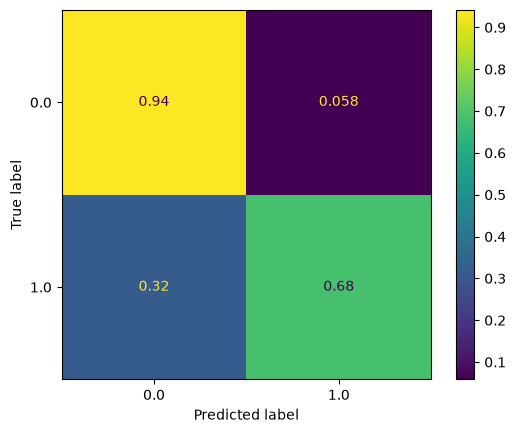

In [96]:
ConfusionMatrixDisplay.from_predictions(y_test, mejor_modelo.predict(X_test), normalize="true");

**Conclusión:** el modelo generaliza bien: la accuracy en test (0.83) es prácticamente igual que en train (0.84) y similar a la de validación cruzada (0.82), así que no hay sobreajuste apreciable. Donde más falla es en la clase positiva: detecta solo el 68% de los supervivientes (recall), aunque cuando predice que alguien sobrevive acierta el 90% de las veces (precision). Si nos interesara más no "perder" supervivientes, podríamos jugar con `class_weight` o con el umbral de decisión.

## **12. ¿Y ahora qué? Predecir pasajeros nuevos**

Imagina que mañana nos llega un pasajero nuevo con sus datos "en crudo" (`pclass`, `sex`, `age`, `fare`...). Para poder predecir su supervivencia tendríamos que aplicarle **exactamente** el mismo preprocesado, en el mismo orden y con lo aprendido en train:

1. `median_imputer.transform(...)` sobre las numéricas
2. `mode_imputer.transform(...)` sobre las categóricas
3. `ohencoder.transform(...)` y concatenar sus columnas eliminando las originales
4. `log_transform.transform(...)` sobre `fare`
5. `std_scaler.transform(...)` sobre `pclass` y las numéricas
6. Pasar todo a `float` y ordenar las columnas como en `X_train`
7. Y por fin, `mejor_modelo.predict(...)`

Es decir, tendríamos que **guardar seis objetos** (cinco transformers y el modelo) más las listas de columnas, y repetir el código a mano sin equivocarnos de orden. Funciona, pero es frágil.

Los transformers nos han ahorrado guardar medias y modas a mano, pero el siguiente paso natural es **encadenarlos en un único objeto** que haga todo esto de una vez: eso son los **Pipelines**, que veremos en los siguientes notebooks.